# Noise-limited whitening of natural images

Use the same `vk_analytical` and `power_residual` functions as the paper notebook (copied below so this notebook runs independently). Optimize a **static, one-dimensional** natural-image spectrum with input and output noise and a unit response-power budget. There is no drift or temporal penalty: `cost = 1`.

The objective is $\frac12\int\log[1+C(k)v(k)/(N_{\rm in}v(k)+N_{\rm out})]\,dk$, subject to $\int(C(k)+N_{\rm in})v(k)\,dk=1$, where $v=|w|^2$. Positive-frequency quadrature weights include the identical negative-frequency contribution.


In [19]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.optimize import brentq
import sys, os 
import matplotlib as mpl

ROOT = Path().resolve().parents[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    "font.size": 7,
})
plt.style.use("../../paper.mplstyle")

%reload_ext autoreload
%autoreload 2

cm = 1 / 2.54
fw = 17.8 * cm
hw = 8.7 * cm

In [ ]:
def vk_analytical(Cx, lam, N_in, N_out, cost=None):
    if cost is None:
        cost = np.ones_like(Cx)

    v = np.zeros_like(Cx, dtype=float)
    mask = Cx > 0
    ratio = Cx[mask] / (Cx[mask] + N_in)
    lam_eff = lam * cost[mask]
    inner = np.sqrt(1.0 + (N_in / N_out) * 2.0 / (lam_eff * Cx[mask]))
    raw = (N_out / N_in) * (ratio * 0.5 * (inner + 1.0) - 1.0)
    v[mask] = np.maximum(raw, 0.0)
    return v


def power_residual(Cx, log_lam, N_in, N_out, weights, cost):
    lam = np.exp(log_lam)
    v = vk_analytical(Cx, lam, N_in, N_out, cost=cost)
    return np.sum(weights * cost * (Cx + N_in) * v) - 1

def plain_formatter():
    return FuncFormatter(lambda value, position: f"{value:g}")

In [56]:
sigma_in, sigma_out = 0.2, 3.0  # edit these to change the noise levels


sf = np.geomspace(0.1, 100, 1000)  # cycles/degree; exclude DC
# Trapezoidal weights on this log-spaced grid, including negative frequencies.
dsf = np.diff(sf)
weights = 2 * np.r_[dsf[0] / 2, (dsf[:-1] + dsf[1:]) / 2, dsf[-1] / 2]

Cx = (2 * np.pi * sf)**-2
Cx /= np.sum(weights * Cx)  # unit signal variance


spectral_area = np.sum(weights)
N_in = sigma_in**2 / spectral_area
N_out = sigma_out**2 / spectral_area
cost = np.ones_like(Cx)  # no temporal or frequency-dependent penalty

log_lam = brentq(
    lambda log_lam: power_residual(Cx, log_lam, N_in, N_out, weights, cost),
    -50, 50,
)
v_opt = vk_analytical(Cx, np.exp(log_lam), N_in, N_out)
output_signal = Cx * v_opt

print(f"Response power = {np.sum(weights * (Cx + N_in) * v_opt):.6f}")


Response power = 1.000000


The output curve is the **signal component** after filtering, $C(k)v(k)$; it excludes both noise contributions. For the total response spectrum including noise, use `(Cx + N_in) * v_opt + N_out`.

The noise floor is shown in the input spectrum's units. Filter power gain has different units, so its height is not a signal-to-noise comparison. Its exact zeros are omitted on the logarithmic axis. Whitening is approximate where signal dominates; the optimized cutoff depends on both noise levels and the power budget, rather than being imposed at $C=N_{
m in}$. Both noise standard deviations must be positive for this closed-form implementation.


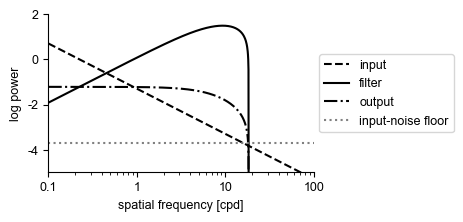

In [62]:
fig, ax = plt.subplots(figsize=(1*hw, 0.6*hw))
ax.semilogx(sf, np.log10(Cx), "k--",label="input")
ax.semilogx(sf, np.log10(np.where(v_opt > 0, v_opt, 1e-10)), "k-", label="filter")
ax.semilogx(sf, np.log10(np.where(output_signal > 0, output_signal, 1e-10)),"k-.", label="output")
ax.axhline(np.log10(N_in), color="grey", linestyle=":", label="input-noise floor")
legend = ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0,
    # frameon=False,
)
# legend.set_in_layout(False)  # keep tight_layout from shrinking the axes

ax.set(
    xlabel="spatial frequency [cpd]",
    ylabel="log power",
    xlim=(sf[0], sf[-1]),
    ylim=(-5,2)
)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.set_major_formatter(plain_formatter())
ax.xaxis.set_major_formatter(plain_formatter())
# ax.legend(fontsize="small", facecolor="white", framealpha=1, edgecolor="none")
# fig.tight_layout()

ROOT = Path.cwd()
if not (ROOT / "main.tex").exists():
    ROOT = ROOT.parent  # when launched from scripts/
(ROOT / "results").mkdir(exist_ok=True)
fig.savefig(ROOT / "results/whitening_optimal_filter.pdf", bbox_inches="tight")
plt.show()
